note: training loop was assisted by claude with a template of my own

# Landmark classifier

DINOv2 (frozen, via `embed.py`) turns each photo into a 384-dim vector. We train one `nn.Linear` on those
vectors to pick a landmark or `other`, then choose a confidence threshold. The result goes into
`data/head.npz`, which `matcher.py` loads.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms.v2 as T
from IPython.display import clear_output
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

from embed import DIM, embed, load

torch.manual_seed(0)

## Photos and labels

One class per non-skipped point, plus `other` (`img/_other`: anything that is *not* one of the landmarks).
The label is the index in `classes`; that order must match the model's outputs, so it is saved with the weights.

In [2]:
points = [p for p in json.load(open("data/points.json", encoding="utf-8")) if not p.get("skip")]
classes = [p["id"] for p in points] + ["other"]
folders = [p["photos"] for p in points] + ["img/_other"]

paths, labels = [], []
for label, folder in enumerate(folders):
    for fname in sorted(os.listdir(folder)):
        if not fname.startswith("."):
            paths.append(os.path.join(folder, fname))
            labels.append(label)

# stratify: every class keeps ~20% of its photos for validation, even the 11-photo one
train_paths, val_paths, train_labels, val_labels = train_test_split(
    paths, labels, test_size=0.2, stratify=labels, random_state=0)

for c, f in zip(classes, folders):
    print(f"{c:18} {labels.count(classes.index(c)):4}  {f}")
print(len(train_paths), "train /", len(val_paths), "val")

petroglyphs          32  img/петроглифы
osudareva-doroga     11  img/памятный_знак
girvas               30  img/гирвас
kivach               31  img/кивач
konchezero           25  img/чугуноплавильный_завод
martsialnye-vody     32  img/марциальные_воды
peter-church         41  img/церковь_петра
peter-monument       36  img/памятник_петру
other               300  img/_other
430 train / 108 val


## Dataset

DINOv2 is frozen, so there's no point running it every epoch: embed each photo once, keep the vectors.
For training photos we also embed a few randomly augmented copies (crops, flips, lighting), which is how
30 photos become 150 training examples. Validation photos are never augmented.

In [3]:
augment = T.Compose([
    T.RandomResizedCrop(320, scale=(0.4, 1.0)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
])


class EmbeddingDataset(Dataset):
    def __init__(self, paths, labels, copies=0):
        X, y = [], []
        for path, label in zip(tqdm(paths), labels):
            img = load(path)
            versions = [img] + [augment(img) for _ in range(copies)]
            X.append(embed(versions))
            y += [label] * len(versions)
        self.X = torch.from_numpy(np.concatenate(X))
        self.y = torch.tensor(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [4]:
train_dataset = EmbeddingDataset(train_paths, train_labels, copies=4)
val_dataset = EmbeddingDataset(val_paths, val_labels)
print(len(train_dataset), "train vectors /", len(val_dataset), "val vectors")

  0%|          | 0/430 [00:00<?, ?it/s]

  0%|          | 0/108 [00:00<?, ?it/s]

2150 train vectors / 108 val vectors


## Model and training loop

In [5]:
# a single linear layer over a few thousand vectors: CPU beats the GPU transfer overhead
device = "cpu"

model = nn.Linear(DIM, len(classes)).to(device)

In [6]:
def train(model, train_dataloader, eval_dataloader, optimizer, loss_fn, epochs):
    train_losses, eval_losses, eval_accs = [], [], []
    for epoch in range(epochs):
        model.train()
        current_train_losses = []
        for X, y in train_dataloader:
            X, y = X.to(device), y.to(device)
            loss = loss_fn(model(X), y)
            current_train_losses.append(loss.item())

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        model.eval()
        current_eval_losses, correct = [], 0
        with torch.no_grad():
            for X, y in eval_dataloader:
                X, y = X.to(device), y.to(device)
                pred = model(X)
                current_eval_losses.append(loss_fn(pred, y).item())
                correct += (pred.argmax(1) == y).sum().item()

        train_losses.append(np.mean(current_train_losses))
        eval_losses.append(np.mean(current_eval_losses))
        eval_accs.append(correct / len(eval_dataloader.dataset))

        if epoch % 10 == 0 or epoch == epochs - 1:
            clear_output(wait=True)
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3))
            ax1.plot(train_losses, label="train")
            ax1.plot(eval_losses, label="eval")
            ax1.set_title(f"loss, epoch {epoch + 1}/{epochs}")
            ax1.legend()
            ax2.plot(eval_accs)
            ax2.set_title(f"eval accuracy {eval_accs[-1]:.3f}")
            plt.show()

`other` has far more photos than any landmark, so without weights the model could do well by just
answering `other` a lot. Weighting each class by 1 / its count makes every class matter equally.

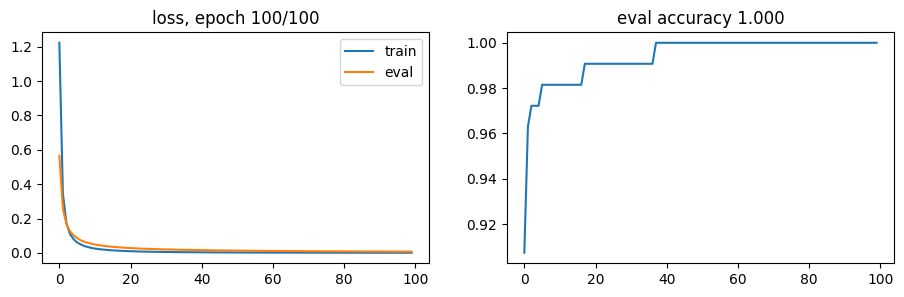

In [7]:
counts = torch.bincount(train_dataset.y, minlength=len(classes)).float()
loss_fn = nn.CrossEntropyLoss(weight=(counts.sum() / (len(classes) * counts)).to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-4)

train(model, DataLoader(train_dataset, batch_size=64, shuffle=True), DataLoader(val_dataset, batch_size=256),
      optimizer, loss_fn, epochs=100)

## Threshold

The site accepts a photo for landmark X when the top guess is X **and** its probability ≥ threshold.
On validation photos:
- a landmark photo's score is its true-class probability (0 if the top guess is wrong);
- an `other` photo's score is its top probability if that top guess is a landmark (0 if it's `other`),
  i.e. how confidently it would sneak through if the user claimed that landmark.

threshold 0.3: landmarks accepted  100%, other wrongly accepted    0%
threshold 0.4: landmarks accepted  100%, other wrongly accepted    0%
threshold 0.5: landmarks accepted  100%, other wrongly accepted    0%
threshold 0.6: landmarks accepted  100%, other wrongly accepted    0%
threshold 0.7: landmarks accepted  100%, other wrongly accepted    0%
threshold 0.8: landmarks accepted  100%, other wrongly accepted    0%
threshold 0.9: landmarks accepted   98%, other wrongly accepted    0%


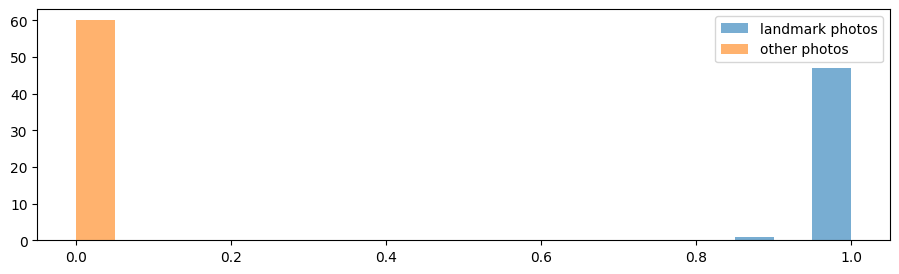

In [8]:
model.eval()
with torch.no_grad():
    probs = model(val_dataset.X.to(device)).softmax(1).cpu().numpy()
y = val_dataset.y.numpy()
guess = probs.argmax(1)
other = classes.index("other")
pos = y != other

pos_score = np.where(guess[pos] == y[pos], probs[pos, y[pos]], 0)
neg_score = np.where(guess[~pos] != other, probs[~pos].max(1), 0)

for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    print(f"threshold {t:.1f}: landmarks accepted {(pos_score >= t).mean():5.0%}, "
          f"other wrongly accepted {(neg_score >= t).mean():5.0%}")

plt.figure(figsize=(11, 3))
plt.hist(pos_score, bins=20, range=(0, 1), alpha=0.6, label="landmark photos")
plt.hist(neg_score, bins=20, range=(0, 1), alpha=0.6, label="other photos")
plt.legend()
plt.show()

The photos it gets wrong are the most useful thing to look at: bad training photos, lookalikes,
or a sign that `img/_other` needs more of a certain kind of picture.

In [9]:
val_paths_arr = np.array(val_paths)
for path, score in zip(val_paths_arr[pos][pos_score < 0.5], pos_score[pos_score < 0.5]):
    print(f"missed   {score:.2f}  {path}")
for path, score, g in zip(val_paths_arr[~pos][neg_score >= 0.5], neg_score[neg_score >= 0.5], guess[~pos][neg_score >= 0.5]):
    print(f"accepted {score:.2f}  {path}  as {classes[g]}")

## Save for the site

In [10]:
THRESHOLD = 0.5

np.savez(
    "data/head.npz",
    W=model.weight.detach().cpu().numpy(),
    b=model.bias.detach().cpu().numpy(),
    classes=np.array(classes),
    threshold=np.float32(THRESHOLD),
)

## Try any photo

In [11]:
def predict(path):
    with torch.no_grad():
        p = model(torch.from_numpy(embed([load(path)])).to(device)).softmax(1)[0].cpu().numpy()
    for i in p.argsort()[::-1][:3]:
        print(f"{classes[i]:18} {p[i]:.2f}")


predict("static/covers/kivach.jpg")

kivach             1.00
other              0.00
girvas             0.00
